#IMPORTING REQUIRED LIBRARIES


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram,linkage
from sklearn.decomposition import PCA

#IMPORTING DATASET IRIS AND CONVERTING INTO A DATAFRAME df

In [3]:
from sklearn.datasets import load_iris
df=pd.DataFrame(load_iris().data,columns=load_iris().feature_names)
df.head(10)#Dispalys 1st 10 rows in the dataframe

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


**As,there is no target feature included into the dataframe, we can use the same dataframe for clustering**

#EXPLORATORY DATA ANALYSIS

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


**from the dataframe information,no null values can be identified**



#STATISTICAL ANALYSIS

In [5]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


#CHECKING DUPLICATES VALUES

In [6]:
duplicates=df.duplicated().sum()
duplicates

np.int64(1)

**One row identified as duplicated.**

#DELETING DUPLICATE ROW

In [7]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

#FINDING OUTLIERS

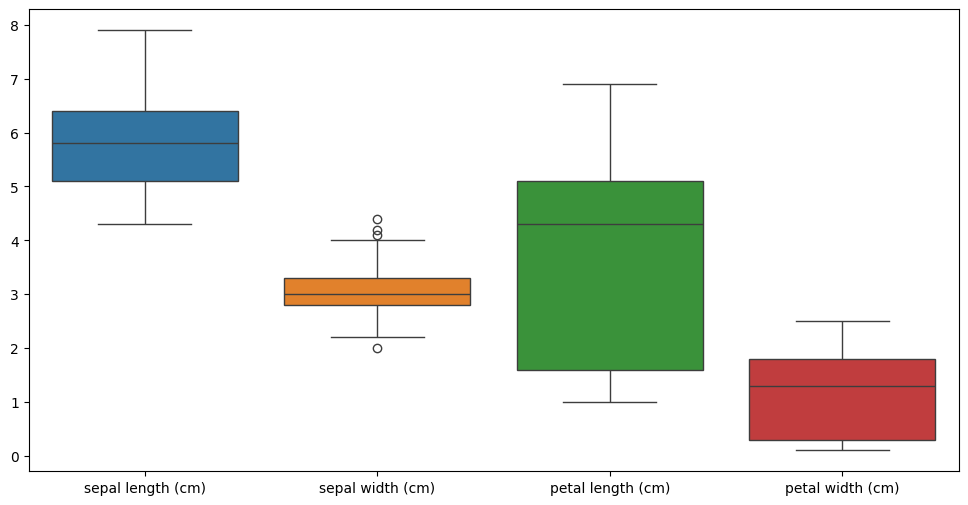

In [9]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df)
plt.show()

**Outliers can be identified for the column sepal width**

# HANDLING OUTLIERS

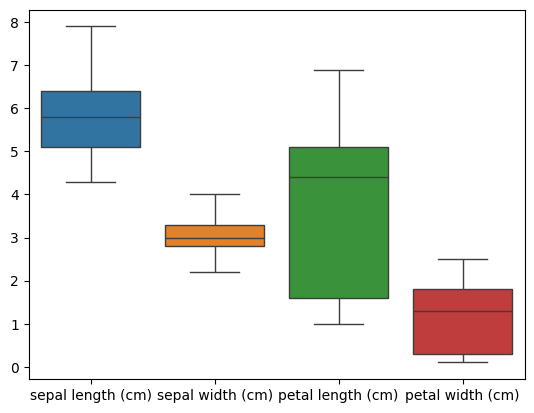

In [15]:
Q1=df["sepal width (cm)"].quantile(0.25)
Q3=df["sepal width (cm)"].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
clean_df=df[(df["sepal width (cm)"]<=upper_bound) & (df["sepal width (cm)"] >=lower_bound)]
sns.boxplot(clean_df)
plt.show()

#FEATURE SCALING

In [20]:
scaler=StandardScaler()
df_scaled=scaler.fit_transform(clean_df)

#1.KMEANS CLUSTERING

**k-Means** groups data into **k clusters**, where:
•	Each cluster has a **centroid** (center)
•	Each point belongs to the nearest centroid

KMEANS Algorithm is best for iris dataset,as its containing only numerical features.Since the dataset is small, clean, and contains relatively well-separated groups, K-Means can effectively identify cluster centroids and partition the data into meaningful clusters.


**Finding K Value using elbow method**

In [21]:
inertia=[]
for i in range(1,11):
  km=KMeans(n_clusters=i,random_state=42)
  km.fit(df_scaled)
  inertia.append(km.inertia_)


**VISUALIZING K VALUES**

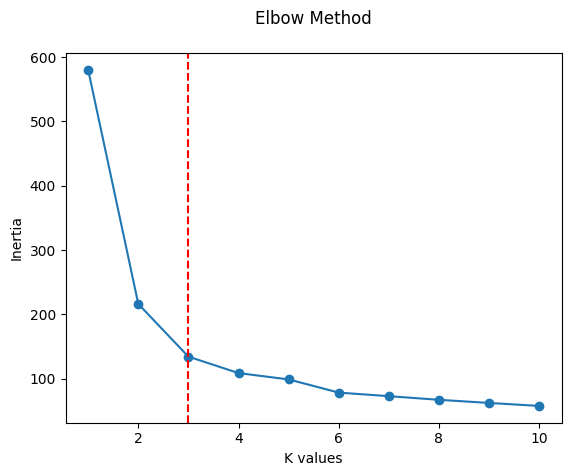

In [34]:
pt=plt.plot(range(1,11),inertia,marker='o')
plt.axvline(x=3, color='red', linestyle='--')
plt.title("Elbow Method\n")
plt.xlabel("K values")
plt.ylabel("Inertia")
plt.show()


**based on  elbow method,value K is bend in value 3,ie:k=3**

#Finding Best K value using silhouette score.

In [35]:
for k in range(2,11):
  km=KMeans(n_clusters=k,random_state=42)
  labels=km.fit_predict(df_scaled)
  score=silhouette_score(df_scaled,labels)
  print(" score of ",k,"value is :",score)

 score of  2 value is : 0.5812849028441721
 score of  3 value is : 0.4615595942122948
 score of  4 value is : 0.42063540999179166
 score of  5 value is : 0.38470400665728666
 score of  6 value is : 0.3383660868573819
 score of  7 value is : 0.30461876344945205
 score of  8 value is : 0.30899374358664555
 score of  9 value is : 0.2987968815273444
 score of  10 value is : 0.2966684009242148


**From Silhouette score ,score is high for k value 2,ie K=2**

#APPLYING KMEANS ALGORITHM-
**taking k=3 from elbow method**

In [37]:
 km=KMeans(n_clusters=3,random_state=42)
 clusters=km.fit_predict(df_scaled)
 clean_df["Clusters"]=clusters
 df.head(150)


/tmp/ipykernel_1023/838384775.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_df["Clusters"]=clusters


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


#CLUSTER ANALYSIS

In [51]:
cluster_summary=clean_df.groupby("Clusters")[["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)" ]].mean()
cluster_summary

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
Clusters,,,,
0,5.768750,2.658333,4.264583,1.354167
1,6.725490,3.082353,5.462745,1.960784
2,4.986957,3.400000,1.465217,0.245652


**VISUALIZATION OF KMEAN** :datapoints clustured around 3

Text(0.5, 1.0, 'Iris dataset  Visualization')

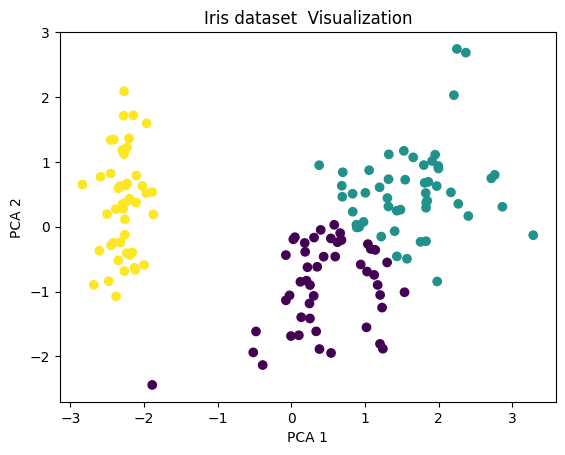

In [53]:
pca=PCA(n_components=2)
pca_data=pca.fit_transform(df_scaled)
plt.scatter(pca_data[:,0], pca_data[:,1], c=clean_df['Clusters'])
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Iris dataset  Visualization')


# **KMEANS INTERPRETATION**



**From KMEANS Clustering Algorithm,datapoints can be classified into 3 clusters**

Cluster 0:High Sepal length and less Sepal width,and moderate petal length and low petal width

Cluster 1:High sepal length and moderate sepal width,and high petal length and less petal width

cluster 2:moderate sepal length and moderate sepal width,and less petal length and less petal width

#2.HEIRARCHICAL CLUSTERING

**Hierarchical clustering** is an unsupervised learning technique that builds a tree-like hierarchy of clusters, instead of producing just one flat partition.

**hierarchical clustering** is also suitable for iris dataset ,as it does not require specifying the number of clusters beforehand and provides a dendrogram that helps visualize the relationships among samples and determine an appropriate number of clusters.

**CREATING DENDROGRAM**

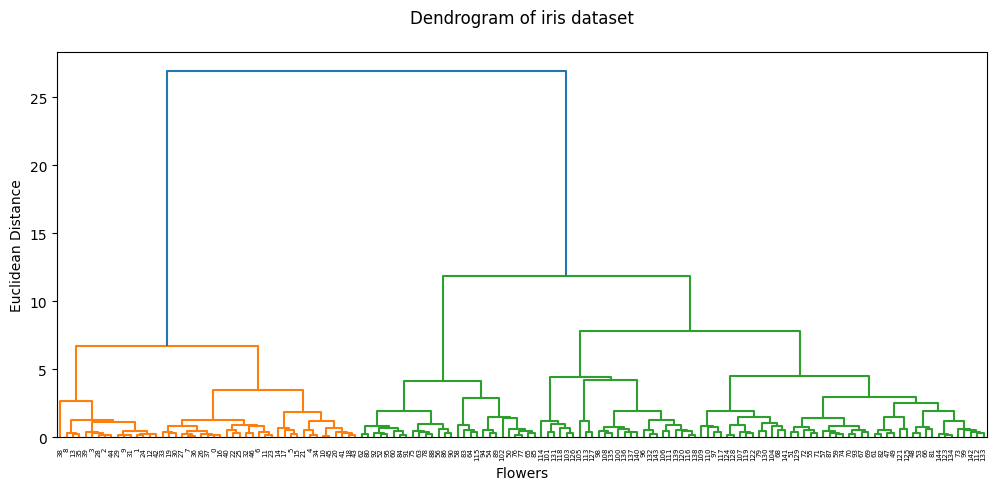

In [57]:
plt.figure(figsize=(12,5))
linked=linkage(df_scaled,method="ward")
dendrogram(linked)
plt.title("Dendrogram of iris dataset\n ")
plt.xlabel("Flowers")
plt.ylabel("Euclidean Distance")
plt.show()

**from Dendrogram we take number of clusters K values as 2**

#APPLYING AGGLOMERATIVE CLUSTERING

In [58]:
Agg=AgglomerativeClustering(n_clusters=2,metric="euclidean",linkage="ward")
Agg_cluster=Agg.fit_predict(df_scaled)
dat=clean_df.drop("Clusters",axis=1)
dat["Agg_cluster"]=Agg_cluster
dat


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Agg_cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,0
146,6.3,2.5,5.0,1.9,0
147,6.5,3.0,5.2,2.0,0
148,6.2,3.4,5.4,2.3,0


#CLUSTER ANALYSIS

In [62]:
Agg_clus=dat.groupby("Agg_cluster")[["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)"]].mean()
Agg_clus

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
Agg_cluster,,,,
0,6.279592,2.882653,4.918367,1.680612
1,4.976596,3.376596,1.461702,0.246809


#VISUALIZING THE AGGLOMERATIVE CLUSTERS

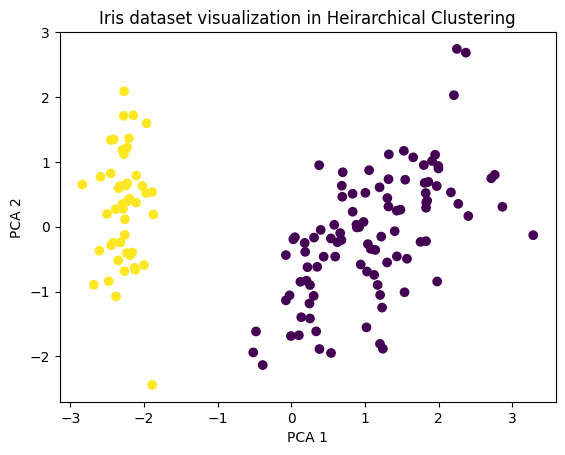

In [65]:
pca=PCA(n_components=2)
pca_data=pca.fit_transform(df_scaled)
plt.scatter(pca_data[:,0],pca_data[:,1],c=dat["Agg_cluster"])
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Iris dataset visualization in Heirarchical Clustering")
plt.show()


#INTERPRETATION

**From dataset,we can find three species,but in Agglomerative dendogram,k value identified as 2**

From Agglomerative Clustering Algorithm,datapoints can be classified into 2 clusters

**Cluster 0**:High Sepal length and less Sepal width,and moderate petal length and low petal width

**Cluster 1**:high sepal length and moderate sepal width,and low petal length and less petal width



#CONCLUSION

So we can conclude that,from **KMEANS Algorithm** ,we get the best K value,so clustering done exactly as the iris dataset species number.

But **AGGLOMERATIVE Algorithm** ,dendogram gave incorrect K values,so for iris dataset ,KMEANS Algorithm is best